In [2]:
import math
import numpy as np
import pandas as pd
import sys
import os
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.signal
from tqdm import tqdm
from statsmodels.stats.multitest import multipletests
import upsetplot as upset

In [3]:
# Gene level APA analysis
apalord_res_nucleus = pd.read_table('Fig2/APA_gene_table_nucleus.txt')
apalord_res_nucleus = apalord_res_nucleus.dropna(subset = ['gene_name'])
apalord_shorter_nucleus = apalord_res_nucleus[apalord_res_nucleus['APA_trend'] == 'shorter']['gene_name'].drop_duplicates().tolist()
apalord_longer_nucleus = apalord_res_nucleus[apalord_res_nucleus['APA_trend'] == 'longer']['gene_name'].drop_duplicates().tolist()

apalord_res_cyto = pd.read_table('Fig2/APA_gene_table_cyto.txt')
apalord_res_cyto = apalord_res_cyto.dropna(subset = ['gene_name'])
apalord_shorter_cyto = apalord_res_cyto[apalord_res_cyto['APA_trend'] == 'shorter']['gene_name'].drop_duplicates().tolist()
apalord_longer_cyto = apalord_res_cyto[apalord_res_cyto['APA_trend'] == 'longer']['gene_name'].drop_duplicates().tolist()

apalord_res_nucleus.head()


,gene_id,short_gene_id,APA_change,pvalue,APA_type,chrom,strand,gene_name,gene_biotype,number_of_PAS,...,PAS_read_counts,PAS_PAUs,PAUs_shCTL_nucleus,PAUs_shPABPN1_nucleus,PAU_changes,reads_shCTL_nucleus,reads_shPABPN1_nucleus,P_adj,APA_trend,log10padj
1,ENSG00000251562,ENSG00000251562,-0.405321,0.000000e+00,Last_exon_tandem_APA,11,+,MALAT1,lncRNA,5,...,"9164,311,783,8128,250","44.44,1.51,3.8,39.41,1.21","15.18,0.7,7.11,63.38,1.21","55.33,1.81,2.56,30.48,1.21","40.15,1.11,-4.55,-32.9,0","850,39,398,3548,68","8314,272,385,4580,182",0.000000e+00,shorter,inf
2,ENSG00000198363,ENSG00000198363,-0.440744,3.419923e-228,Mixed_APA,8,-,ASPH,protein_coding,12,...,"223,1012,77,1630,1079,153,90,121,142,138,215,130","3.8,17.25,1.31,27.79,18.39,2.61,1.53,2.06,2.42...","6.74,24.12,1.09,44.21,8.4,0.57,0.33,1.14,0.57,...","2.15,13.4,1.44,18.59,23.99,3.75,2.21,2.58,3.46...","-4.59,-10.72,0.35,-25.62,15.59,3.18,1.88,1.44,...","142,508,23,931,177,12,7,24,12,16,0,42","81,504,54,699,902,141,83,97,130,122,215,88",1.271527e-224,shorter,223.895674
3,ENSG00000145495,ENSG00000145495,-0.240228,1.198812e-154,Last_exon_tandem_APA,5,+,MARCHF6,protein_coding,5,...,"266,3430,1320,302,3919","2.15,27.72,10.67,2.44,31.67","0.99,21.31,10.83,3.73,42.38","3.15,33.26,10.53,1.33,22.43","2.16,11.95,-0.3,-2.4,-19.95","57,1222,621,214,2430","209,2208,699,88,1489",2.971456e-151,shorter,150.527031
4,ENSG00000145592,ENSG00000145592,0.305606,1.025821e-138,Last_exon_tandem_APA,5,-,RPL37,protein_coding,4,...,"1822,103,3228,2172","22.83,1.29,40.45,27.22","19.73,0.61,23.87,46.6","24.22,1.6,47.88,18.54","4.49,0.99,24.01,-28.06","487,15,589,1150","1335,88,2639,1022",1.907001e-135,longer,134.719649
5,ENSG00000150991,ENSG00000150991,0.000000,4.349347e-134,Last_exon_tandem_APA,12,-,UBC,protein_coding,2,...,"15351,21532","39.26,55.07","47.36,47.99","34.63,59.12","-12.73,11.13","6742,6833","8609,14699",6.468349e-131,no change,130.189207


c:\Users\bacs5867\PycharmProjects\pythonProject\.venv\Lib\site-packages\upsetplot\plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  styles["linewidth"].fillna(1, inplace=True)
c:\Users\bacs5867\PycharmProjects\pythonProject\.venv\Lib\site-packages\upsetplot\plotting.py:796: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on whi

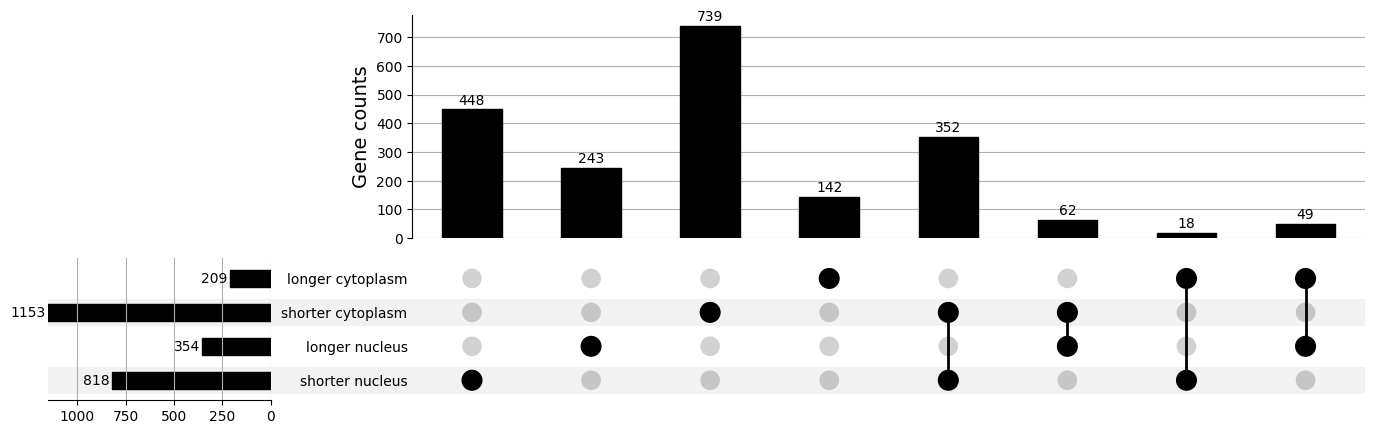

In [4]:
# upsetplot overlaps genes with APA
df_upset = apalord_res_nucleus[['gene_name']].drop_duplicates().merge(apalord_res_cyto[['gene_name']].drop_duplicates(), how = 'outer')
df_upset['shorter nucleus'] = False
df_upset['longer nucleus'] = False
df_upset['shorter cytoplasm'] = False
df_upset['longer cytoplasm'] = False
df_upset.loc[df_upset['gene_name'].isin(apalord_shorter_nucleus), 'shorter nucleus'] = True
df_upset.loc[df_upset['gene_name'].isin(apalord_longer_nucleus), 'longer nucleus'] = True
df_upset.loc[df_upset['gene_name'].isin(apalord_shorter_cyto), 'shorter cytoplasm'] = True
df_upset.loc[df_upset['gene_name'].isin(apalord_longer_cyto), 'longer cytoplasm'] = True
df_upset = df_upset[(df_upset['shorter nucleus'] != False) | (df_upset['longer nucleus'] != False) | (df_upset['shorter cytoplasm'] != False) | (df_upset['longer cytoplasm'] != False)]
df_upset = df_upset.groupby(by = ['shorter nucleus', 'longer nucleus', 'shorter cytoplasm', 'longer cytoplasm'])['gene_name'].count()

fig = plt.figure(figsize=(17, 5))
upset.plot(df_upset, show_counts=True, fig = fig, element_size=None, sort_categories_by = 'input')
plt.title('')
plt.ylabel('Gene counts', fontsize = 14)
plt.show()

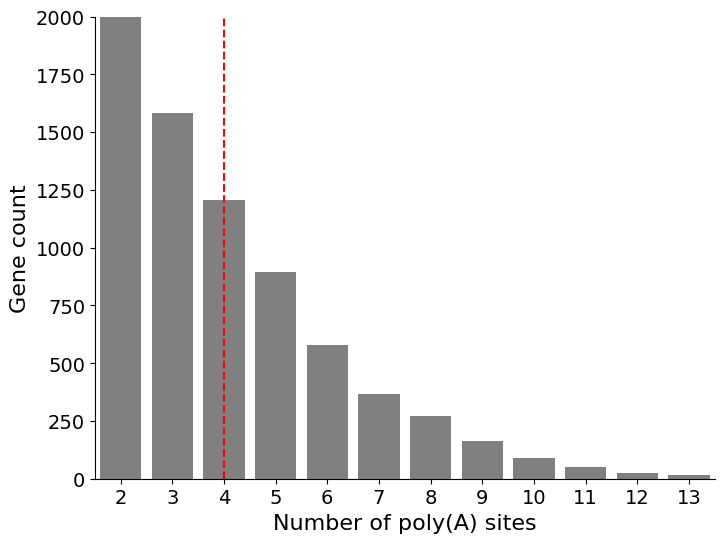

In [5]:
# barplot number of PAS per gene
# nucleus
apalord_res_nucleus_sites_count = apalord_res_nucleus.groupby(by = 'number_of_PAS')['gene_name'].count().reset_index()
apalord_res_nucleus_sites_count_list = np.repeat(apalord_res_nucleus_sites_count["number_of_PAS"], apalord_res_nucleus_sites_count["gene_name"])
apalord_res_nucleus_sites_count_median = apalord_res_nucleus_sites_count_list.median()

fig, axes = plt.subplots(figsize=(8, 6))
sns.barplot(data = apalord_res_nucleus_sites_count[apalord_res_nucleus_sites_count['number_of_PAS'] < 14], x = 'number_of_PAS', y = 'gene_name', color = 'grey')
plt.xlabel('Number of poly(A) sites', fontsize = 16)
plt.ylabel('Gene count', fontsize = 16)
plt.tick_params(labelsize = 14)
plt.axvline(x = 2, color = 'red', linestyle = '--') # x = 2 means 3rd bar of the barplot, adapt to the value of the median
plt.ylim(0,2000)
sns.despine()

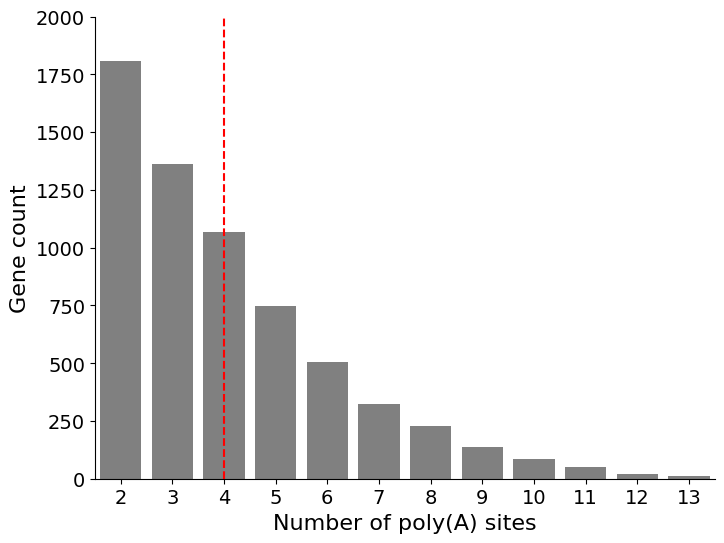

In [6]:
# cytoplasm
apalord_res_cyto_sites_count = apalord_res_cyto.groupby(by = 'number_of_PAS')['gene_name'].count().reset_index()
apalord_res_cyto_sites_count_list = np.repeat(apalord_res_cyto_sites_count["number_of_PAS"], apalord_res_cyto_sites_count["gene_name"])
apalord_res_cyto_sites_count_median = apalord_res_cyto_sites_count_list.median()

fig, axes = plt.subplots(figsize=(8, 6))
sns.barplot(data = apalord_res_cyto_sites_count[apalord_res_cyto_sites_count['number_of_PAS'] < 14], x = 'number_of_PAS', y = 'gene_name', color = 'grey')
plt.xlabel('Number of poly(A) sites', fontsize = 16)
plt.ylabel('Gene count', fontsize = 16)
plt.tick_params(labelsize = 14)
plt.axvline(x = 2, color = 'red', linestyle = '--') # x = 2 means 3rd bar of the barplot, adapt to the value of the median
plt.ylim(0,2000)
sns.despine()

In [16]:
# PAS level analysis
apalord_PAU_nucleus = pd.read_table('Fig2/nucleus_PAU_stats.txt', index_col=[0])
apalord_PAU_cyto = pd.read_table('Fig2/cyto_PAU_stats.txt', index_col=[0])

apalord_PAU_nucleus.head()

,PAS_name,gene_id,chrom,strand,gene_name,PAS,stat,pvalue,padj,shCTL_nucleus,shPABPN1_nucleus,log2fold_shPABPN1_nucleus_shCTL_nucleus,countData.C..Users.bacs5867.Documents.PABPN1.isoquant.dorado_new.shCTL_noyau_rep2,countData.C..Users.bacs5867.Documents.PABPN1.isoquant.dorado_new.shCTL_noyau_rep3,countData.C..Users.bacs5867.Documents.PABPN1.isoquant.dorado_new.shNT_noyau,countData.C..Users.bacs5867.Documents.PABPN1.isoquant.dorado_new.shPAB_noyau_rep2,countData.C..Users.bacs5867.Documents.PABPN1.isoquant.dorado_new.shPAB_noyau_rep3,countData.C..Users.bacs5867.Documents.PABPN1.isoquant.dorado_new.shPAB_noyau
1,ENSG00000000419:50934870,ENSG00000000419,20,-,DPM1,50934870,0.166278,0.683441,0.909460,1.948993,1.930282,-0.062876,31,44,304,68,36,418
2,ENSG00000000419:50934958,ENSG00000000419,20,-,DPM1,50934958,0.165198,0.684415,0.909707,0.957707,0.997610,0.148159,7,4,19,5,7,46
3,ENSG00000000457:169849631,ENSG00000000457,1,-,SCYL3,169849631,3.182491,0.074431,0.350027,1.091519,1.255430,0.583933,6,2,35,12,6,144
4,ENSG00000000457:169853089,ENSG00000000457,1,-,SCYL3,169853089,4.779114,0.028807,0.200020,1.557925,1.362902,-0.671320,16,14,83,22,14,115
5,ENSG00000000457:169887458,ENSG00000000457,1,-,SCYL3,169887458,3.343218,0.067482,0.331888,0.364063,0.597261,1.171458,1,0,4,1,3,21


In [9]:
##### dictionnary of start and stop codons
with open ('C:/Users/bacs5867/Documents/PABPN1/analyse/hg38_genome_ensembl_114/Homo_sapiens.GRCh38.114.gtf', 'r') as gtf :
    start_codons = {}
    stop_codons = {}
    for line in gtf :
        line = line.strip('\n').split('\t')
        try :
            if "Ensembl_canonical" in line[8] :
                if line[2] == 'stop_codon' :
                    ensembl_id = line[8].split(';')[0]
                    for char in ["'", "gene_id", '"', ' ']:
                        ensembl_id = ensembl_id.replace(char, '')
                    stop_codons[ensembl_id] = line[3]
                if line[2] == 'start_codon':
                    ensembl_id = line[8].split(';')[0]
                    for char in ["'", "gene_id", '"', ' ']:
                        ensembl_id = ensembl_id.replace(char, '')
                    start_codons[ensembl_id] = line[3]
        except :
            print(line)

['#!genome-build GRCh38.p14']
['#!genome-version GRCh38']
['#!genome-date 2013-12']
['#!genome-build-accession GCA_000001405.29']
['#!genebuild-last-updated 2024-11']


In [11]:
ensembl_id_hg38_114_gtf = pd.read_table('C:/Users/bacs5867/Documents/PABPN1/analyse/hg38_genome_ensembl_114/Homo_sapiens.GRCh38.114_ensembl_gene_names.txt', index_col=[0])
ensembl_id_hg38_114_gtf['stop_codon'] = ensembl_id_hg38_114_gtf['Geneid'].map(stop_codons)
gene_id_stop = ensembl_id_hg38_114_gtf[['Geneid', 'stop_codon']].drop_duplicates().rename(columns = {'Geneid' : 'gene_id'})

ensembl_id_hg38_114_gtf

,Geneid,gene_name,stop_codon
0,ENSG00000142611,PRDM16,3433809
1,ENSG00000157911,PEX10,2405766
2,ENSG00000224340,RPL21P21,NaN
3,ENSG00000229280,EEF1DP6,NaN
4,ENSG00000142655,PEX14,10629985
...,...,...,...
42755,ENSG00000274917,RNA5-8SN5,NaN
42756,ENSG00000273730,5_8S_rRNA,NaN
42757,ENSG00000277374,U1,NaN
42758,ENSG00000275987,U1,NaN


In [12]:
def prox_dist(gene_id, strand, site, apalord_PAU) :
    df = apalord_PAU[apalord_PAU['gene_id'] == gene_id]
    site_max = df['PAS'].max()
    site_min = df['PAS'].min()
    if strand == '+' :
        if site == site_max :
            return('distal')
        elif site == site_min:
            return('proximal')
        else :
            return('other')
    elif strand == '-' :
        if site == site_max :
            return('proximal')
        elif site == site_min:
            return('distal')
        else :
            return('other')


def cryptic_UTR(strand, site, stop_codon) :
    try :
        if strand == '+' :
            if site > int(stop_codon) :
                return('3UTR')
            elif site < int(stop_codon) :
                return('cryptic')
        elif strand == '-' :
            if site > int(stop_codon):
                return ('cryptic')
            elif site < int(stop_codon):
                return ('3UTR')
    except :
        return('unknown')

In [17]:
apalord_PAU_nucleus = apalord_PAU_nucleus.merge(gene_id_stop, on = 'gene_id', how = 'left')
apalord_PAU_nucleus['site_prox_dist'] = apalord_PAU_nucleus.apply(lambda row: prox_dist(row.gene_id, row.strand, row.PAS, apalord_PAU_nucleus), axis = 1)
apalord_PAU_nucleus['site_3UTR_cryptic'] = apalord_PAU_nucleus.apply(lambda row: cryptic_UTR(row.strand, row.PAS, row.stop_codon), axis = 1)
apalord_PAU_nucleus.loc[apalord_PAU_nucleus['site_prox_dist'] == 'distal', 'site_3UTR_cryptic'] = 'distal'
apalord_PAU_nucleus['diff_usage'] = 'not_sig'
apalord_PAU_nucleus.loc[(apalord_PAU_nucleus['padj'] <= 0.05) & (apalord_PAU_nucleus['log2fold_shPABPN1_nucleus_shCTL_nucleus'] >= 1), 'diff_usage'] = 'increased'
apalord_PAU_nucleus.loc[(apalord_PAU_nucleus['padj'] <= 0.05) & (apalord_PAU_nucleus['log2fold_shPABPN1_nucleus_shCTL_nucleus'] <= -(1)), 'diff_usage'] = 'decreased'

apalord_PAU_nucleus.head()

,PAS_name,gene_id,chrom,strand,gene_name,PAS,stat,pvalue,padj,shCTL_nucleus,...,countData.C..Users.bacs5867.Documents.PABPN1.isoquant.dorado_new.shCTL_noyau_rep2,countData.C..Users.bacs5867.Documents.PABPN1.isoquant.dorado_new.shCTL_noyau_rep3,countData.C..Users.bacs5867.Documents.PABPN1.isoquant.dorado_new.shNT_noyau,countData.C..Users.bacs5867.Documents.PABPN1.isoquant.dorado_new.shPAB_noyau_rep2,countData.C..Users.bacs5867.Documents.PABPN1.isoquant.dorado_new.shPAB_noyau_rep3,countData.C..Users.bacs5867.Documents.PABPN1.isoquant.dorado_new.shPAB_noyau,stop_codon,site_prox_dist,site_3UTR_cryptic,diff_usage
0,ENSG00000000419:50934870,ENSG00000000419,20,-,DPM1,50934870,0.166278,0.683441,0.909460,1.948993,...,31,44,304,68,36,418,50935132,distal,distal,not_sig
1,ENSG00000000419:50934958,ENSG00000000419,20,-,DPM1,50934958,0.165198,0.684415,0.909707,0.957707,...,7,4,19,5,7,46,50935132,proximal,3UTR,not_sig
2,ENSG00000000457:169849631,ENSG00000000457,1,-,SCYL3,169849631,3.182491,0.074431,0.350027,1.091519,...,6,2,35,12,6,144,169853713,distal,distal,not_sig
3,ENSG00000000457:169853089,ENSG00000000457,1,-,SCYL3,169853089,4.779114,0.028807,0.200020,1.557925,...,16,14,83,22,14,115,169853713,other,3UTR,not_sig
4,ENSG00000000457:169887458,ENSG00000000457,1,-,SCYL3,169887458,3.343218,0.067482,0.331888,0.364063,...,1,0,4,1,3,21,169853713,proximal,cryptic,not_sig


In [18]:
apalord_PAU_cyto = apalord_PAU_cyto.merge(gene_id_stop, on = 'gene_id', how = 'left')
apalord_PAU_cyto['site_prox_dist'] = apalord_PAU_cyto.apply(lambda row: prox_dist(row.gene_id, row.strand, row.PAS, apalord_PAU_cyto), axis = 1)
apalord_PAU_cyto['site_3UTR_cryptic'] = apalord_PAU_cyto.apply(lambda row: cryptic_UTR(row.strand, row.PAS, row.stop_codon), axis = 1)
apalord_PAU_cyto.loc[apalord_PAU_cyto['site_prox_dist'] == 'distal', 'site_3UTR_cryptic'] = 'distal'
apalord_PAU_cyto['diff_usage'] = 'not_sig'
apalord_PAU_cyto.loc[(apalord_PAU_cyto['padj'] <= 0.05) & (apalord_PAU_cyto['log2fold_shPABPN1_cyto_shCTL_cyto'] >= 1), 'diff_usage'] = 'increased'
apalord_PAU_cyto.loc[(apalord_PAU_cyto['padj'] <= 0.05) & (apalord_PAU_cyto['log2fold_shPABPN1_cyto_shCTL_cyto'] <= -(1)), 'diff_usage'] = 'decreased'

C:\Users\bacs5867\AppData\Local\Temp\ipykernel_24452\861476712.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  apalord_PAU_nucleus_status_sites_count_increased['proportion'] = apalord_PAU_nucleus_status_sites_count_increased['gene_id'] / apalord_PAU_nucleus_status_sites_count_increased['gene_id'].sum()
C:\Users\bacs5867\AppData\Local\Temp\ipykernel_24452\861476712.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  apalord_PAU_nucleus_status_sites_count_notsig['proportion'] = apalord_PAU_nucleus_status_

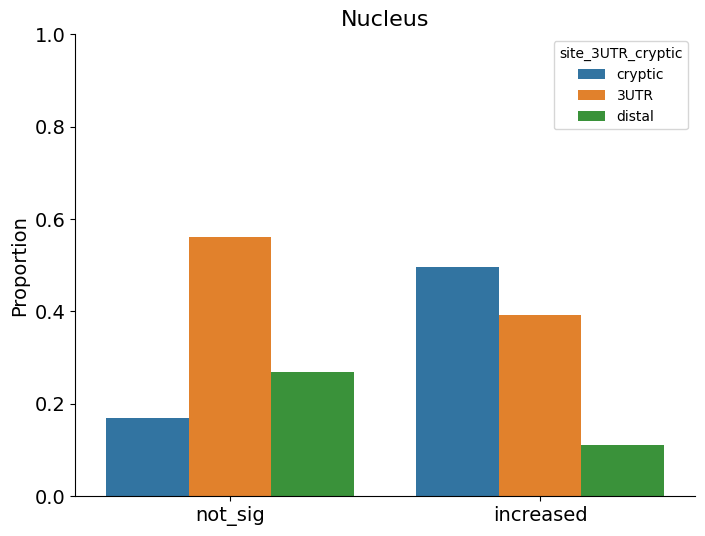

In [19]:
apalord_PAU_nucleus_status_sites_count = apalord_PAU_nucleus.groupby(by = ['diff_usage', 'site_3UTR_cryptic'])['gene_id'].count().reset_index()
apalord_PAU_nucleus_status_sites_count = apalord_PAU_nucleus_status_sites_count[(apalord_PAU_nucleus_status_sites_count['diff_usage'] != 'decreased') & (apalord_PAU_nucleus_status_sites_count['site_3UTR_cryptic'] != 'unknown')]
apalord_PAU_nucleus_status_sites_count_increased = apalord_PAU_nucleus_status_sites_count[apalord_PAU_nucleus_status_sites_count['diff_usage'] == 'increased']
apalord_PAU_nucleus_status_sites_count_increased['proportion'] = apalord_PAU_nucleus_status_sites_count_increased['gene_id'] / apalord_PAU_nucleus_status_sites_count_increased['gene_id'].sum()
apalord_PAU_nucleus_status_sites_count_notsig = apalord_PAU_nucleus_status_sites_count[apalord_PAU_nucleus_status_sites_count['diff_usage'] == 'not_sig']
apalord_PAU_nucleus_status_sites_count_notsig['proportion'] = apalord_PAU_nucleus_status_sites_count_notsig['gene_id'] / apalord_PAU_nucleus_status_sites_count_notsig['gene_id'].sum()
apalord_PAU_nucleus_status_sites_count = pd.concat([apalord_PAU_nucleus_status_sites_count_notsig, apalord_PAU_nucleus_status_sites_count_increased]).reset_index(drop = True)

fig, axes = plt.subplots(figsize=(8, 6))
sns.barplot(data = apalord_PAU_nucleus_status_sites_count, x = 'diff_usage', y = 'proportion', hue = 'site_3UTR_cryptic', hue_order=['cryptic', '3UTR', 'distal'])
plt.xlabel('')
plt.title('Nucleus', fontsize = 16)
plt.ylabel('Proportion', fontsize = 14)
plt.tick_params(labelsize = 14)
plt.ylim(0,1)
sns.despine()


In [25]:
# stat test
apalord_PAU_nucleus_status_sites_count_piv = apalord_PAU_nucleus_status_sites_count.pivot_table(index = ['diff_usage'], columns = 'site_3UTR_cryptic', values = 'gene_id')
chi2, p_nucleus, dof, expected = stats.chi2_contingency(apalord_PAU_nucleus_status_sites_count_piv)

print('pvalue nucleus = ' + str(p_nucleus))


pvalue nucleus = 9.506807753818869e-122


C:\Users\bacs5867\AppData\Local\Temp\ipykernel_24452\2891541904.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  apalord_PAU_cyto_status_sites_count_increased['proportion'] = apalord_PAU_cyto_status_sites_count_increased['gene_id'] / apalord_PAU_cyto_status_sites_count_increased['gene_id'].sum()
C:\Users\bacs5867\AppData\Local\Temp\ipykernel_24452\2891541904.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  apalord_PAU_cyto_status_sites_count_notsig['proportion'] = apalord_PAU_cyto_status_sites_count_n

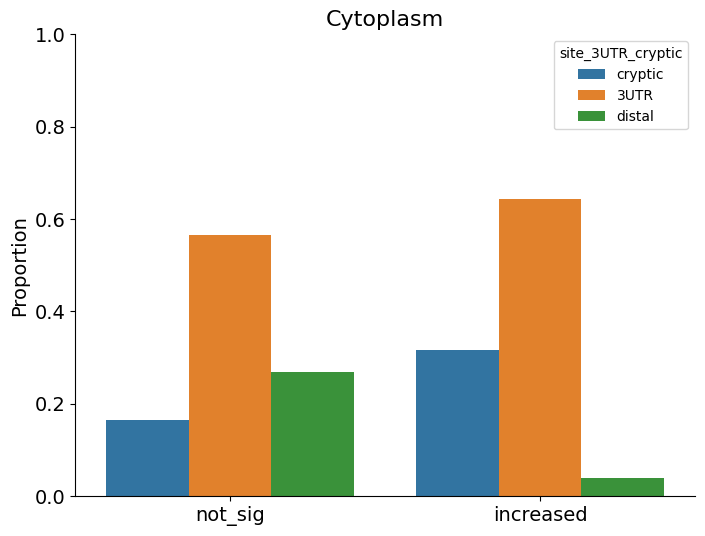

In [22]:
apalord_PAU_cyto_status_sites_count = apalord_PAU_cyto.groupby(by = ['diff_usage', 'site_3UTR_cryptic'])['gene_id'].count().reset_index()
apalord_PAU_cyto_status_sites_count = apalord_PAU_cyto_status_sites_count[(apalord_PAU_cyto_status_sites_count['diff_usage'] != 'decreased') & (apalord_PAU_cyto_status_sites_count['site_3UTR_cryptic'] != 'unknown')]
apalord_PAU_cyto_status_sites_count_increased = apalord_PAU_cyto_status_sites_count[apalord_PAU_cyto_status_sites_count['diff_usage'] == 'increased']
apalord_PAU_cyto_status_sites_count_increased['proportion'] = apalord_PAU_cyto_status_sites_count_increased['gene_id'] / apalord_PAU_cyto_status_sites_count_increased['gene_id'].sum()
apalord_PAU_cyto_status_sites_count_notsig = apalord_PAU_cyto_status_sites_count[apalord_PAU_cyto_status_sites_count['diff_usage'] == 'not_sig']
apalord_PAU_cyto_status_sites_count_notsig['proportion'] = apalord_PAU_cyto_status_sites_count_notsig['gene_id'] / apalord_PAU_cyto_status_sites_count_notsig['gene_id'].sum()
apalord_PAU_cyto_status_sites_count = pd.concat([apalord_PAU_cyto_status_sites_count_notsig, apalord_PAU_cyto_status_sites_count_increased]).reset_index(drop = True)

fig, axes = plt.subplots(figsize=(8, 6))
sns.barplot(data = apalord_PAU_cyto_status_sites_count, x = 'diff_usage', y = 'proportion', hue = 'site_3UTR_cryptic', hue_order=['cryptic', '3UTR', 'distal'])
plt.xlabel('')
plt.title('Cytoplasm', fontsize = 16)
plt.ylabel('Proportion', fontsize = 14)
plt.tick_params(labelsize = 14)
plt.ylim(0,1)
sns.despine()

In [24]:
# stat test
apalord_PAU_cyto_status_sites_count_piv = apalord_PAU_cyto_status_sites_count.pivot_table(index = ['diff_usage'], columns = 'site_3UTR_cryptic', values = 'gene_id')
chi2, p_cyto, dof, expected = stats.chi2_contingency(apalord_PAU_cyto_status_sites_count_piv)

print('pvalue cytoplasm = ' + str(p_cyto))


pvalue cytoplasm = 6.753342944684469e-81


In [ ]:
# extraction of PAS positions

apalord_PAU_nucleus_bed = apalord_PAU_nucleus
apalord_PAU_nucleus_bed['start'] = apalord_PAU_nucleus_bed['PAS'] - 15
apalord_PAU_nucleus_bed['end'] = apalord_PAU_nucleus_bed['PAS'] + 15
apalord_PAU_nucleus_bed = apalord_PAU_nucleus_bed[['chrom', 'start', 'end', 'gene_id', 'PAS', 'strand', 'diff_usage', 'site_3UTR_cryptic', 'gene_name']]

apalord_PAU_cyto_bed = apalord_PAU_cyto
apalord_PAU_cyto_bed['start'] = apalord_PAU_cyto_bed['PAS'] - 15
apalord_PAU_cyto_bed['end'] = apalord_PAU_cyto_bed['PAS'] + 15
apalord_PAU_cyto_bed = apalord_PAU_cyto_bed[['chrom', 'start', 'end', 'gene_id', 'PAS', 'strand', 'diff_usage', 'site_3UTR_cryptic', 'gene_name']]

apalord_PAU_nucleus_bed.head()

,chrom,start,end,gene_id,PAS,strand,diff_usage,site_3UTR_cryptic,gene_name
0,20,50934855,50934885,ENSG00000000419,50934870,-,not_sig,distal,DPM1
1,20,50934943,50934973,ENSG00000000419,50934958,-,not_sig,3UTR,DPM1
2,1,169849616,169849646,ENSG00000000457,169849631,-,not_sig,distal,SCYL3
3,1,169853074,169853104,ENSG00000000457,169853089,-,not_sig,3UTR,SCYL3
4,1,169887443,169887473,ENSG00000000457,169887458,-,not_sig,cryptic,SCYL3


Intersection of PAS bed and read ends bed with bedtools intersect

In [ ]:
read_ends_nucleus_PAU = pd.read_table('Fig2/read_ends_nucleus_PAU_reduced.txt', header = None, dtype={0:'str'})
read_ends_nucleus_PAU.columns = ['chrom', 'start', 'end', 'read', 'score', 'strand', 'polya_length', 'gene_id', 'shRNA', 'gene_id2', 'PAS', 'diff_usage', 'site_3UTR_cryptic', 'gene_name']
read_ends_nucleus_PAU = read_ends_nucleus_PAU[read_ends_nucleus_PAU['gene_id'] == read_ends_nucleus_PAU['gene_id2']] # make sure genes are the same - eliminate duplicates
read_ends_nucleus_PAU = read_ends_nucleus_PAU[read_ends_nucleus_PAU['polya_length'] != 0]
read_ends_nucleus_PAU_median = read_ends_nucleus_PAU.groupby(by = ['gene_name', 'shRNA', 'PAS', 'diff_usage', 'site_3UTR_cryptic'])['polya_length'].median().reset_index()
read_ends_nucleus_PAU_count = read_ends_nucleus_PAU.groupby(by = ['gene_name', 'shRNA', 'PAS', 'diff_usage', 'site_3UTR_cryptic'])['read'].count().reset_index()
read_ends_nucleus_PAU_median = read_ends_nucleus_PAU_median.merge(read_ends_nucleus_PAU_count[read_ends_nucleus_PAU_count['read'] >= 20], on = ['gene_name', 'shRNA', 'PAS', 'diff_usage', 'site_3UTR_cryptic'])
read_ends_nucleus_PAU_median['condition'] = read_ends_nucleus_PAU_median['shRNA'] + ' nucleus'

read_ends_cyto_PAU = pd.read_table('Fig2/read_ends_cyto_PAU_reduced.txt', header = None, dtype={0:'str'})
read_ends_cyto_PAU.columns = ['chrom', 'start', 'end', 'read', 'score', 'strand', 'polya_length', 'gene_id', 'shRNA', 'gene_id2', 'PAS', 'diff_usage', 'site_3UTR_cryptic', 'gene_name']
read_ends_cyto_PAU = read_ends_cyto_PAU[read_ends_cyto_PAU['gene_id'] == read_ends_cyto_PAU['gene_id2']] # make sure genes are the same - eliminate duplicates
read_ends_cyto_PAU = read_ends_cyto_PAU[read_ends_cyto_PAU['polya_length'] != 0]
read_ends_cyto_PAU_median = read_ends_cyto_PAU.groupby(by = ['gene_name', 'shRNA', 'PAS', 'diff_usage', 'site_3UTR_cryptic'])['polya_length'].median().reset_index()
read_ends_cyto_PAU_count = read_ends_cyto_PAU.groupby(by = ['gene_name', 'shRNA', 'PAS', 'diff_usage', 'site_3UTR_cryptic'])['read'].count().reset_index()
read_ends_cyto_PAU_median = read_ends_cyto_PAU_median.merge(read_ends_cyto_PAU_count[read_ends_cyto_PAU_count['read'] >= 20], on = ['gene_name', 'shRNA', 'PAS', 'diff_usage', 'site_3UTR_cryptic'])
read_ends_cyto_PAU_median['condition'] = read_ends_cyto_PAU_median['shRNA'] + ' cytoplasm'

read_ends_PAU_median = pd.concat([read_ends_nucleus_PAU_median, read_ends_cyto_PAU_median]).reset_index(drop = True)

read_ends_PAU_median.head()


FileNotFoundError: [Errno 2] No such file or directory: 'C:/Users/bacs5867/Documents/PABPN1/isoquant/dorado_new/read_ends_nucleus_PAU_reduced.txt'

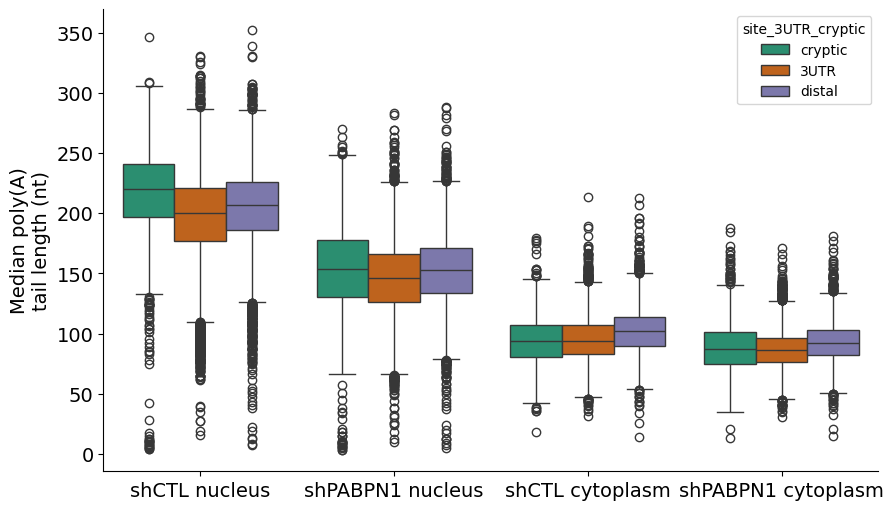

In [21]:
fig, axes = plt.subplots(figsize=(10, 6))
sns.boxplot(data = read_ends_PAU_median, x = 'condition', y = 'polya_length', hue = 'site_3UTR_cryptic', palette = 'Dark2', hue_order=['cryptic', '3UTR', 'distal'])
plt.xlabel('')
plt.ylabel('Median poly(A)\ntail length (nt)', fontsize = 14)
plt.tick_params(labelsize = 14)
sns.despine()

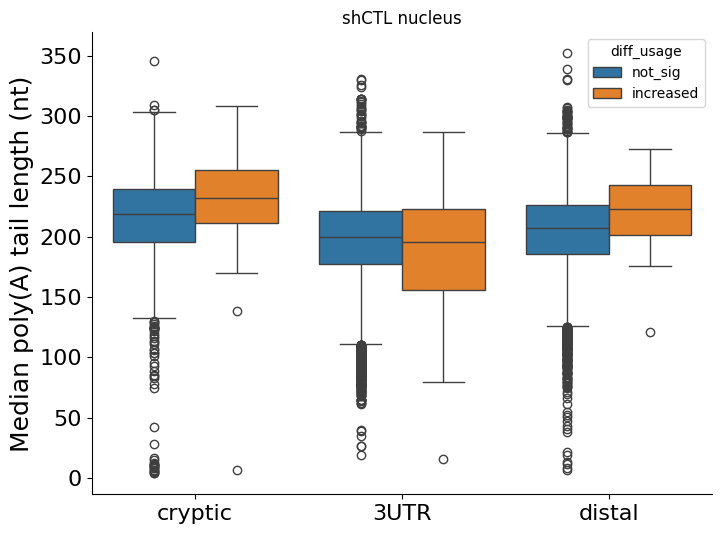

In [25]:
read_ends_PAU_median_shCTL_nucleus_boxplot = read_ends_PAU_median[(read_ends_PAU_median['condition'] == 'shCTL nucleus') & (read_ends_PAU_median['site_3UTR_cryptic'] != 'unknown')]

fig, axes = plt.subplots(figsize=(8, 6))
sns.boxplot(data = read_ends_PAU_median_shCTL_nucleus_boxplot[read_ends_PAU_median_shCTL_nucleus_boxplot['diff_usage'] != 'decreased'], x = 'site_3UTR_cryptic', y = 'polya_length', hue = 'diff_usage', order = ['cryptic', '3UTR', 'distal'])
plt.xlabel('')
plt.title('shCTL nucleus')
plt.ylabel('Median poly(A) tail length (nt)', fontsize = 18)
plt.tick_params(labelsize = 16)
sns.despine()


In [27]:
# stat test
for site in ['cryptic', '3UTR', 'distal'] :
    print(site)
    list_increased = read_ends_PAU_median_shCTL_nucleus_boxplot[(read_ends_PAU_median_shCTL_nucleus_boxplot['site_3UTR_cryptic'] == site) &
                                                                    (read_ends_PAU_median_shCTL_nucleus_boxplot['diff_usage'] == 'increased')]['polya_length'].tolist()
    list_decreased = read_ends_PAU_median_shCTL_nucleus_boxplot[(read_ends_PAU_median_shCTL_nucleus_boxplot['site_3UTR_cryptic'] == site) &
                                                                    (read_ends_PAU_median_shCTL_nucleus_boxplot['diff_usage'] == 'decreased')]['polya_length'].tolist()
    list_nosig = read_ends_PAU_median_shCTL_nucleus_boxplot[(read_ends_PAU_median_shCTL_nucleus_boxplot['site_3UTR_cryptic'] == site) &
                                                                    (read_ends_PAU_median_shCTL_nucleus_boxplot['diff_usage'] == 'not_sig')]['polya_length'].tolist()
    pvalue_increased = stats.mannwhitneyu(x = list_nosig, y = list_increased)[1]
    pvalue_decreased = stats.mannwhitneyu(x=list_nosig, y=list_decreased)[1]
    print('pvalue increased = ' + str(pvalue_increased))
    print('pvalue decreased = ' + str(pvalue_decreased))

cryptic
pvalue increased = 9.510924702913567e-06
pvalue decreased = 0.3539464805249011
3UTR
pvalue increased = 0.18906464662760203
pvalue decreased = 0.7158446881853326
distal
pvalue increased = 0.0009179689769873202
pvalue decreased = 0.0014715109129022528


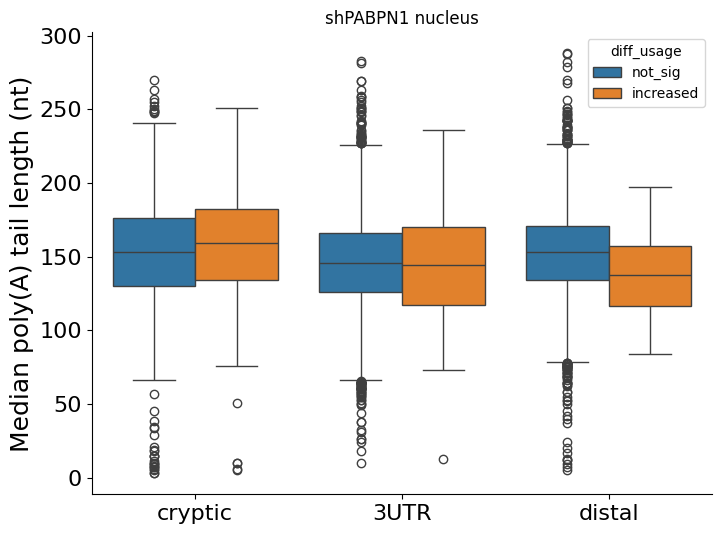

In [26]:
read_ends_PAU_median_shPABPN1_nucleus_boxplot = read_ends_PAU_median[(read_ends_PAU_median['condition'] == 'shPABPN1 nucleus') & (read_ends_PAU_median['site_3UTR_cryptic'] != 'unknown')]

fig, axes = plt.subplots(figsize=(8, 6))
sns.boxplot(data = read_ends_PAU_median_shPABPN1_nucleus_boxplot[read_ends_PAU_median_shPABPN1_nucleus_boxplot['diff_usage'] != 'decreased'], x = 'site_3UTR_cryptic', y = 'polya_length', hue = 'diff_usage', order = ['cryptic', '3UTR', 'distal'])
plt.xlabel('')
plt.title('shPABPN1 nucleus')
plt.ylabel('Median poly(A) tail length (nt)', fontsize = 18)
plt.tick_params(labelsize = 16)
sns.despine()

In [28]:
# stat test
for site in ['cryptic', '3UTR', 'distal'] :
    print(site)
    list_increased = read_ends_PAU_median_shPABPN1_nucleus_boxplot[(read_ends_PAU_median_shPABPN1_nucleus_boxplot['site_3UTR_cryptic'] == site) &
                                                                    (read_ends_PAU_median_shPABPN1_nucleus_boxplot['diff_usage'] == 'increased')]['polya_length'].tolist()
    list_decreased = read_ends_PAU_median_shPABPN1_nucleus_boxplot[(read_ends_PAU_median_shPABPN1_nucleus_boxplot['site_3UTR_cryptic'] == site) &
                                                                    (read_ends_PAU_median_shPABPN1_nucleus_boxplot['diff_usage'] == 'decreased')]['polya_length'].tolist()
    list_nosig = read_ends_PAU_median_shPABPN1_nucleus_boxplot[(read_ends_PAU_median_shPABPN1_nucleus_boxplot['site_3UTR_cryptic'] == site) &
                                                                    (read_ends_PAU_median_shPABPN1_nucleus_boxplot['diff_usage'] == 'not_sig')]['polya_length'].tolist()
    pvalue_increased = stats.mannwhitneyu(x = list_nosig, y = list_increased)[1]
    pvalue_decreased = stats.mannwhitneyu(x=list_nosig, y=list_decreased)[1]
    print('pvalue increased = ' + str(pvalue_increased))
    print('pvalue decreased = ' + str(pvalue_decreased))


cryptic
pvalue increased = 0.01425316003528621
pvalue decreased = 0.8542666991942425
3UTR
pvalue increased = 0.3852560643822518
pvalue decreased = 0.6118084227353056
distal
pvalue increased = 0.00013046066892589592
pvalue decreased = 0.0641904183162926
